In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import sys
import yaml
from pathlib import Path
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from scipy.spatial.distance import hamming


import warnings
warnings.filterwarnings("ignore")

In [2]:
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)

seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'

In [3]:
def qual_to_float(qual):
    return list(map(ord, qual))
def make_substrings(s, K):
    return [s[i: j] for i in range(len(s)) for j in range(i + 1, len(s) + 1) if len(s[i:j]) == K]

# Counts

In [169]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

In [170]:
df

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-02-02-TP1_S20_L001,sym-02-02-TP1_S20_L002,sym-03-01-TP4_S46_L001,sym-03-01-TP4_S46_L002,sym-02-01-TP2_S22_L001,sym-02-01-TP2_S22_L002,sym-03-02-TP2_S41_L001,sym-03-02-TP2_S41_L002,sym-03-02-TP4_S47_L001,sym-03-02-TP4_S47_L002
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,744,726,771,748,754,763,593,642,869,878
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,1142,1151,1112,1133,930,1010,914,971,1252,1198
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,696,647,608,641,593,630,617,582,824,856
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,588,556,507,475,409,435,438,361,638,630
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,968,949,870,915,856,845,733,785,1043,1158
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA258:258-280,CCACCACCCTTTACACGGACACG,280.0,0.891826,CDS,631.0,...,208,211,125,103,72,95,218,224,185,150
RPS16_ENST00000251453_300,ENST00000251453,ENSG00000105193,RPS16,protein_coding,crRNA278:278-300,CATAAATCTGGGCCACGTGACCA,300.0,0.892320,CDS,631.0,...,132,179,62,58,42,37,102,125,70,85
RPS5_ENST00000196551_431,ENST00000196551,ENSG00000083845,RPS5,protein_coding,crRNA409:409-431,CCACTGTTGATGATGGCGTTCAC,431.0,1.006859,CDS,741.0,...,199,203,328,342,62,62,424,397,376,411


In [176]:
sample_names = list(df.columns[12:])

In [177]:
sample_names

['sym-02-02-TP6_S35_L001',
 'sym-02-02-TP6_S35_L002',
 'sym-02-03-TP1_S21_L001',
 'sym-02-03-TP1_S21_L002',
 'sym-02-01-TP4_S28_L001',
 'sym-02-01-TP4_S28_L002',
 'sym-03-03-TP5_S51_L001',
 'sym-03-03-TP5_S51_L002',
 'sym-01-02-TP3_S8_L001',
 'sym-01-02-TP3_S8_L002',
 'sym-03-01-TP5_S49_L001',
 'sym-03-01-TP5_S49_L002',
 'sym-03-03-TP6_S54_L001',
 'sym-03-03-TP6_S54_L002',
 'sym-02-02-TP2_S23_L001',
 'sym-02-02-TP2_S23_L002',
 'sym-03-01-TP3_S43_L001',
 'sym-03-01-TP3_S43_L002',
 'sym-01-02-TP5_S14_L001',
 'sym-01-02-TP5_S14_L002',
 'sym-02-02-TP4_S29_L001',
 'sym-02-02-TP4_S29_L002',
 'sym-01-01-TP2_S4_L001',
 'sym-01-01-TP2_S4_L002',
 'sym-01-01-TP6_S16_L001',
 'sym-01-01-TP6_S16_L002',
 'sym-02-01-TP1_S19_L001',
 'sym-02-01-TP1_S19_L002',
 'sym-01-03-TP2_S6_L001',
 'sym-01-03-TP2_S6_L002',
 'sym-01-01-TP1_S1_L001',
 'sym-01-01-TP1_S1_L002',
 'sym-03-01-TP1_S37_L001',
 'sym-03-01-TP1_S37_L002',
 'sym-01-03-TP5_S15_L001',
 'sym-01-03-TP5_S15_L002',
 'sym-03-03-TP2_S42_L001',
 'sym-03-

# Trimming

In [4]:
def trim_sequence(read, quality):
    K = len(seq_primer)
    
    # search primer in expected region
    subs = make_substrings(read[pmin:pmax+K], K)
    weights = make_substrings(quality[pmin:pmax+K], K)
    primer_alignment = pd.DataFrame(index=np.arange(len(subs)), columns=['idx', 'sequence', 'hamming_distance'])
    for j, sub, w in zip(range(len(subs)), subs, weights):
        ham = hamming(list(seq_primer), list(sub), qual_to_float(w))
        primer_alignment.iloc[j] = [j+pmin, sub, ham]
    primer_alignment = primer_alignment.sort_values('hamming_distance')
    primer_idx, primer_hit, primer_distance = primer_alignment.iloc[0]
    primer_certainty = primer_alignment.hamming_distance.iloc[1] - primer_alignment.hamming_distance.iloc[0]
    
    # select guide position after primer
    trimmed_seq = read[primer_idx+K : primer_idx+K+guide_length]
    trimmed_qual = quality[primer_idx+K : primer_idx+K+guide_length]
    
    return trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty

In [5]:
# deep one
file = path / 'sym-01-01-TP1_S1_L001_R1_001.fastq'

In [14]:
def process(line1, line2, line3, line4):
    index = line1
    sequence = line2.replace('\n', '')
    qual = line4.replace('\n', '')

    trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
    return index, trimmed_seq, trimmed_qual

def chunker(seq, size):
    return (seq[pos:pos + size] for pos in range(0, len(seq), size))

# Parallel processing
with open(file, 'r') as INPUT:
    lines = INPUT.readlines()[:10000]
    n_reads = int(len(lines) / 4)
    results = Parallel(n_jobs=4)(delayed(process)(line1, line2, line3, line4) for line1, line2, line3, line4 in tqdm(chunker(lines, size=4), total=n_reads))

# write to file
with open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    for index, trimmed_seq, trimmed_qual in tqdm(results, total=n_reads):
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')

  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/2500 [00:00<?, ?it/s]

## Eval trimming

In [24]:
qcs = {x.name.split('_R1_001')[0]: pd.read_csv(x, sep='\t') for x in (Path(config['TEMPDIR']) /'pooled_screen_1/trimmed/qc').glob('*')}
df = pd.concat(qcs).droplevel(1)

In [26]:
df['fraction_filtered'] = df.Filtered_reads / df.Total_reads
df['group'] = [x.split('-')[1] for x in df.index]
df['lane'] = [x.split('_')[-1] for x in df.index]

In [28]:
df.head()

,Mean_primer_distance,Mean_primer_certainty,Filtered_reads,Total_reads,fraction_filtered,group,lane
sym-03-01-TP2_S40_L001,0.393326,0.186740,146127,3752185,0.038945,03,L001
sym-01-02-TP5_S14_L002,0.391821,0.192538,386904,7378938,0.052434,01,L002
sym-03-02-TP2_S41_L001,0.394498,0.185374,154890,3864224,0.040083,03,L001
sym-02-02-TP6_S35_L001,0.396969,0.182575,138160,3814596,0.036219,02,L001
sym-03-01-TP6_S52_L001,0.396831,0.182833,153899,4265629,0.036079,03,L001


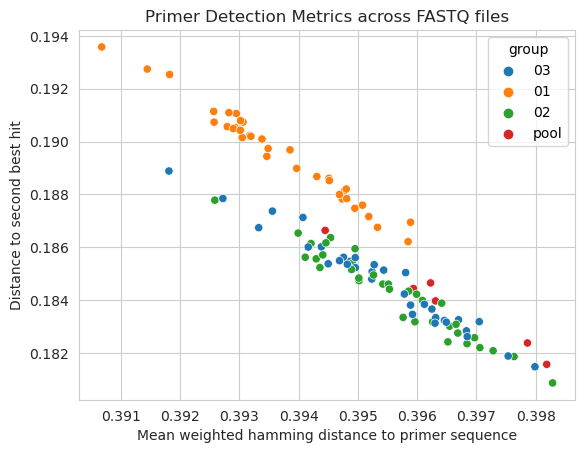

In [52]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.scatterplot(data=df, x='Mean_primer_distance', hue='group', y='Mean_primer_certainty', ax=ax)
pl.xlabel('Mean weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.title('Primer Detection Metrics across FASTQ files')
pl.show()

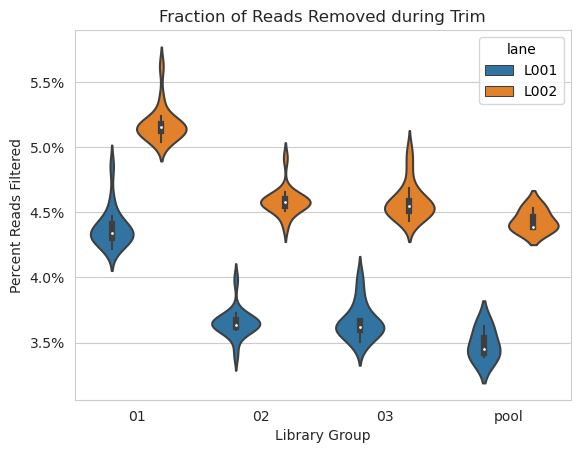

In [41]:
import matplotlib.ticker as mtick
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.violinplot(data=df, x='group', hue='lane', y='fraction_filtered', ax=ax, order=['01', '02', '03', 'pool'])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1,1))
pl.ylabel('Percent Reads Filtered')
pl.xlabel('Library Group')
pl.title('Fraction of Reads Removed during Trim')
pl.show()

## Finding cut-offs

In [9]:
# deep one
file = path / 'sym-01-01-TP1_S1_L001_R1_001.fastq'

dat = []
with open(file, 'r') as INPUT, \
     open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)
    for i in tqdm(range(n_reads)):
        index = lines[4*i]
        sequence = lines[4*i+1].replace('\n', '')
        qual = lines[4*i+3].replace('\n', '')
        
        trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
        dat.append([primer_distance, primer_certainty])
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')
        
        if i>10000:
            break

  0%|          | 0/11277957 [00:00<?, ?it/s]

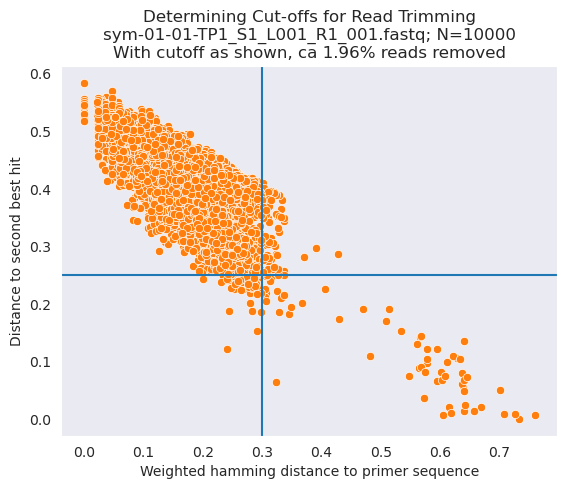

In [10]:
df = pd.DataFrame(dat, columns=['primer_distance', 'primer_certainty'])
with sns.axes_style('dark'):
    sns.scatterplot(data=df, x='primer_distance', y='primer_certainty', c='tab:orange')
xcut = 0.3
ycut = 0.25
removal = np.round(100 - 100 * len(df[(df.primer_distance < 0.3) & (df.primer_certainty > 0.25)]) / len(df), 2)
pl.axvline(xcut)
pl.axhline(ycut)
pl.title(f'Determining Cut-offs for Read Trimming\n{file.name}; N=10000\nWith cutoff as shown, ca {removal}% reads removed')
pl.xlabel('Weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.show()

In [11]:
# a shallow one
file = path / 'sym-02-01-TP1_S19_L001_R1_001.fastq'

dat = []
with open(file, 'r') as INPUT, \
     open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)
    for i in tqdm(range(n_reads)):
        index = lines[4*i]
        sequence = lines[4*i+1].replace('\n', '')
        # line 3 is just "+"
        qual = lines[4*i+3].replace('\n', '')
        
        trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
        dat.append([primer_distance, primer_certainty])
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')
        
        if i>10000:
            break

  0%|          | 0/5025827 [00:00<?, ?it/s]

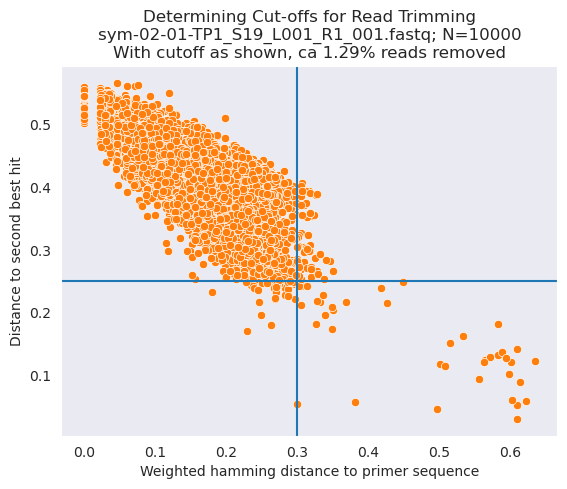

In [12]:
df = pd.DataFrame(dat, columns=['primer_distance', 'primer_certainty'])
with sns.axes_style('dark'):
    sns.scatterplot(data=df, x='primer_distance', y='primer_certainty', c='tab:orange')
xcut = 0.3
ycut = 0.25
removal = np.round(100 - 100 * len(df[(df.primer_distance < 0.3) & (df.primer_certainty > 0.25)]) / len(df), 2)
pl.axvline(xcut)
pl.axhline(ycut)
pl.title(f'Determining Cut-offs for Read Trimming\n{file.name}; N=10000\nWith cutoff as shown, ca {removal}% reads removed')
pl.xlabel('Weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.show()

# Guide counting (outdated)

In [65]:
guide_df = pd.read_csv('../resources/all_gRNA_data.csv', index_col='unique_guide_name')
guide_df.head()

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,gRNA_occurence,transcript_per_gene
unique_guide_name,,,,,,,,,,,,
CYP26B1_ENST00000001146_2702,ENST00000001146,ENSG00000003137,CYP26B1,protein_coding,crRNA2661:2680-2702,TTAAACCCAAATAATGCCCGGAG,2702.0,1.306530,UTR3,4556.0,1,2
CYP26B1_ENST00000001146_4708,ENST00000001146,ENSG00000003137,CYP26B1,protein_coding,crRNA4464:4686-4708,AAGCCTATAGAAGAGCCACATTG,4708.0,1.411459,UTR3,4556.0,1,2
NDUFAB1_ENST00000007516_654,ENST00000007516,ENSG00000004779,NDUFAB1,protein_coding,crRNA632:632-654,AAGTCCATCAGAATCACTCTGTC,654.0,1.012291,UTR3,665.0,1,1
NDUFAB1_ENST00000007516_667,ENST00000007516,ENSG00000004779,NDUFAB1,protein_coding,crRNA645:645-667,ACAATTTAAATACAAGTCCATCA,667.0,0.996597,UTR3,665.0,1,1
RPS20_ENST00000009589_568,ENST00000009589,ENSG00000008988,RPS20,protein_coding,crRNA508:546-568,CTTTATATTCCTAAAATCTGCCA,568.0,0.821865,UTR3,519.0,1,1


## New

In [55]:
# deep one
input_file = Path(config['TEMPDIR']) / 'pooled_screen_1/trimmed/sym-01-01-TP1_S1_L001_R1_001_custom_trimmed.fastq'

In [78]:
def identify_guide(sequence, quality, quality_cutoff=60):    
    qual = qual_to_float(quality)
    lowest_q = np.min(qual)
    
    high_quality = lowest_q > quality_cutoff
    direct_hit = sequence in guide_df.GuideSeq

    # Find guide
    if high_quality and direct_hit:
        # search for direct hit
        row = guide_df[guide_df.GuideSeq==sequence].iloc[0]
        guide_id = row.index
        guide_hit = row.GuideSeq
        guide_score = 1
        guide_certainty = 1
        next_best_guide = 'None'
    else:
        if not high_quality:
            print(sequence, ' Not trusting the quality!, quality >=', lowest_q)
        else:
            print(sequence, ' High quality, but no direct hit!, quality >=', lowest_q)
        # search best-fitting guide
        guide_alignment = pd.DataFrame(index=np.arange(len(guide_df)), columns=['guide_id', 'guide_sequence', 'score'])
        for j, index, guide in zip(range(len(guide_df)), guide_df.index, guide_df.GuideSeq):
            ham = hamming(list(sequence), list(guide), qual)
            guide_alignment.iloc[j] = [index, guide, 1 - ham]
        guide_alignment = guide_alignment.sort_values('score')
        guide_id, guide_hit, guide_score = guide_alignment.iloc[0]
        guide_certainty = guide_alignment.score.iloc[1] - guide_alignment.score.iloc[0]
        next_best_guide = guide_alignment.guide_id.iloc[1]
    
    return [guide_id, guide_hit, guide_score, guide_certainty, next_best_guide]

def chunker(seq, size):
    return (seq[pos:pos + size] for pos in range(0, len(seq), size))

In [56]:
with open(input_file, 'r') as INPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)

In [79]:
iterator = chunker(lines, 4)
i = 0
res = []
for line1, line2, line3, line4 in iterator:
    index = line1
    sequence = line2.replace('\n', '')
    qual = line4.replace('\n', '')
    
    re = identify_guide(sequence, qual)
    res.append(re)
    
    i+=1
    if i>30:
        break

GCCTGTACTTTGGGGTGACTGCA  Not trusting the quality!, quality >= 58
AGACATTACTAATTTTGCCAGTC  High quality, but no direct hit!, quality >= 70
AAGCCAAGATCAACACACACTGG  High quality, but no direct hit!, quality >= 70
GAGGCACTATCAGATTAGCCCTA  Not trusting the quality!, quality >= 58
CCAACAGATCAGAGGACCCCATA  High quality, but no direct hit!, quality >= 70
GTGAAAGTACTACTACAGACACG  High quality, but no direct hit!, quality >= 70
TTGCACGTCAAATCTGGGGCTGA  High quality, but no direct hit!, quality >= 70
TGCACAAATCAGTGCCTGTCCCA  High quality, but no direct hit!, quality >= 70
TCCTCAATTTCTCCAAAGCCCGT  High quality, but no direct hit!, quality >= 70
ATCCAAGTGTAGATCTGCAACTC  High quality, but no direct hit!, quality >= 70
TCTCGGACACTTAGACCCACTGA  High quality, but no direct hit!, quality >= 70
TAGCAGCAAAACTTCCGGGAACA  Not trusting the quality!, quality >= 58
CCTTGAAGTAATAGACACCAGTC  Not trusting the quality!, quality >= 58
ATGAGATCAACCTTTTCCACCAG  High quality, but no direct hit!, quality >= 70
CCTTCT

In [88]:
tab = pd.DataFrame(res, columns='guide_id, guide_hit, guide_score, guide_certainty, next_best_guide'.split(', '))

In [109]:
tab.head()

,guide_id,guide_hit,guide_score,guide_certainty,next_best_guide
0,LNCARSR_ENST00000413352_1399,AATGTCTTCCATAAAGTGGCCAT,0.000000,0.000000,RPS17_ENST00000559187_346
1,SAMM50_ENST00000350028_1614,GCCTTGCTGCTGCCCCAGTCCCA,0.000000,0.000000,HOTTIP_ENST00000521028_546
2,RPL36AL_ENST00000298289_95,CGCAGCTCTCGCCTTTCGCAGCT,0.000000,0.043478,TMSB4X_ENST00000451311_100
3,CASC15_ENST00000605917_3867,AGAAATTGCAGTTTAAGCACAGT,0.043805,0.000000,SBNO1_ENST00000267176_3063
4,ELOB_ENST00000572954_27,TGCTGCCTCTCCCCTCGACGCGC,0.043478,0.000000,LDHA_ENST00000422447_628


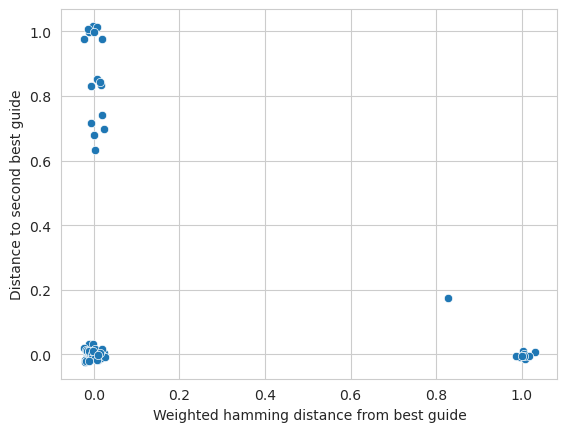

In [108]:
# add jitter
stab = tab.copy()
stab.guide_score = (stab.guide_score + np.random.normal(0, 0.0005, len(stab.guide_score)))*guide_length
stab.guide_certainty = (stab.guide_certainty + np.random.normal(0, 0.0005, len(stab.guide_certainty)))*guide_length

with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.scatterplot(data=stab, x='guide_score', y='guide_certainty', ax=ax)
pl.xlabel('Weighted hamming distance from best guide')
pl.ylabel('Distance to second best guide')
pl.show()

## old

In [303]:
res = []
indices = []
df = pd.DataFrame(index=ids, columns='guide_id, guide_hit, guide_score, guide_certainty, next_best_guide, primer_idx, primer_hit, primer_score, primer_certainty'.split(', '))
for i in tqdm(range(20)):
    df.loc[ids[i]] = identify_guide(sequences[i], qual[i])

  0%|          | 0/20 [00:00<?, ?it/s]

AACAGACATTACTAATTTTGCCA  guide seq was likely not found in guide list!, quality >= 70


  5%|▌         | 1/20 [00:00<00:10,  1.78it/s]

AACAGACATTACTAATTTTGCCA  guide seq was likely not found in guide list!, quality >= 70


 10%|█         | 2/20 [00:01<00:10,  1.78it/s]

AGACATTACTAATTTTGCCAGTC  guide seq was likely not found in guide list!, quality >= 70


... (17 outputs left out)

AGACATTACTAATTTTGCCAGTC  guide seq was likely not found in guide list!, quality >= 70


 95%|█████████▌| 19/20 [00:10<00:00,  1.77it/s]

AGACATTACTAATTTTGCCAGTC  guide seq was likely not found in guide list!, quality >= 70


100%|██████████| 20/20 [00:11<00:00,  1.77it/s]


In [286]:
df.dropna()

,guide_id,guide_hit,guide_score,guide_certainty,next_best_guide,primer_idx,primer_hit,primer_score,primer_certainty
@A00510:908:HW3NNDRX3:1:2101:1994:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTTCCAAAAGTACGCCGTTTGAAAC,0.202162,0.378378
@A00510:908:HW3NNDRX3:1:2101:3676:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTACCAAAAGTACCCCGTTTGAAAC,0.232932,0.358434
@A00510:908:HW3NNDRX3:1:2101:3947:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,CTDP1_ENST00000299543_1020,AAAGAGATTTCTAAGGTTTCCCG,0.304348,0.0,PLRG1_ENST00000302078_812,31,ACCCCTACCAACTTGTCGGGCTTTGAAAC,0.065979,0.51134
@A00510:908:HW3NNDRX3:1:2101:6605:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGGGTTTGAAAC,0.071211,0.430315
@A00510:908:HW3NNDRX3:1:2101:8847:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGTGTAAGAAAC,0.149269,0.41858
@A00510:908:HW3NNDRX3:1:2101:8919:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGGCTTTCAAAC,0.120763,0.431144
@A00510:908:HW3NNDRX3:1:2101:10963:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,BBS2_ENST00000245157_1980,AACAGAAAGTTCTGACCGAGCCA,0.347826,0.0,RHEB_ENST00000472642_442,30,ACCCCTACCTACTGTACTCGCAATGAAAC,0.252289,0.427263
@A00510:908:HW3NNDRX3:1:2101:11650:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTTCCAAAAGTACGCCGTTTGAAAC,0.223577,0.355691
@A00510:908:HW3NNDRX3:1:2101:13259:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,AGCCCTACCAAATGGTCGGGGTTTGAAAC,0.053628,0.443743
@A00510:908:HW3NNDRX3:1:2101:13277:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,CTDP1_ENST00000299543_1020,AAAGAGATTTCTAAGGTTTCCCG,0.304348,0.0,PLRG1_ENST00000302078_812,31,ACCCCTACCAACTGGTCCGCCTTTGAAAC,0.103448,0.482759


In [234]:
df.dropna()

,guide_id,guide_hit,guide_score,guide_certainty,next_best_guide,primer_idx,primer_hit,primer_score,primer_certainty
@A00510:908:HW3NNDRX3:1:2101:1994:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTTCCAAAAGTACGCCGTTTGAAAC,0.202162,0.378378
@A00510:908:HW3NNDRX3:1:2101:3676:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTACCAAAAGTACCCCGTTTGAAAC,0.232932,0.358434
@A00510:908:HW3NNDRX3:1:2101:3947:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,CTDP1_ENST00000299543_1020,AAAGAGATTTCTAAGGTTTCCCG,0.304348,0.0,PLRG1_ENST00000302078_812,31,ACCCCTACCAACTTGTCGGGCTTTGAAAC,0.065979,0.51134
@A00510:908:HW3NNDRX3:1:2101:6605:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGGGTTTGAAAC,0.071211,0.430315
@A00510:908:HW3NNDRX3:1:2101:8847:1031 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTTCCTACTGGTCGGTGTAAGAAAC,0.149269,0.41858
...,...,...,...,...,...,...,...,...,...
@A00510:908:HW3NNDRX3:1:2101:5439:1078 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTTCCAAAAGTACCCGGTTTGAAAC,0.218014,0.306039
@A00510:908:HW3NNDRX3:1:2101:5602:1078 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTACCTACTGGTCGGTCTAAGAAAC,0.135762,0.471302
@A00510:908:HW3NNDRX3:1:2101:5620:1078 1:N:0:ATGTTGCCAC+TAGAAGCCAT,RCE1_ENST00000309657_714,GCAGCAGACAAGAAGATGTTCCC,0.434783,0.043478,FALEC_ENST00000416894_200,28,ACCCCTACCAACTGGTCGGGCTATCAAAC,0.079434,0.522307
@A00510:908:HW3NNDRX3:1:2101:9218:1078 1:N:0:ATGTTGCCAC+TAGAAGCCAT,HNRNPU_ENST00000440865_180,AGACATTACTAATTTTGCCAGTC,0.0,0.347826,DAP3_ENST00000368336_1668,33,ACCCCTACCAAAAGTACCCCGTTTGAAAC,0.231537,0.349301
